# 03 · Usage floor loss

Notebook 02 showed that PaletteNet loses 1 to 3 of its 8 tones in every seed,
and that fewer dead tones means lower reconstruction error. It also showed that
dead tones distort recoloring, because they still receive new colors.

Setup: the same 5 seeds are trained twice, without and with the floor loss.
Everything else is identical. Both configurations use the new assignment, so
differences between them come from the loss alone. The "no floor" runs should
reproduce the numbers from notebook 02, which works as a sanity check.

In [14]:
import os

import kornia
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from dotenv import load_dotenv

from aquarelab.baseline import extract_palette_kmeans
from aquarelab.losses import (
    entropy_loss,
    palette_from_weights,
    reconstruct,
    reconstruction_loss,
    usage_floor_loss,
)
from aquarelab.model import PaletteNet
from aquarelab.recolor import assign_by_luminance, hex_to_lab, lab_to_rgb, recolor

os.makedirs("figures", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
load_dotenv()
print("HF_TOKEN loaded:", os.environ.get("HF_TOKEN") is not None)

Using device: cpu
HF_TOKEN loaded: True


In [15]:
img = Image.open("data/florest.jpg").convert("RGB").resize((256, 256))
rgb = torch.from_numpy(np.asarray(img) / 255.0).float().permute(2, 0, 1)[None].to(device)
lab = kornia.color.rgb_to_lab(rgb)

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
net_input = (rgb - mean) / std

image_np = rgb[0].permute(1, 2, 0).cpu().numpy()  # (H, W, 3) RGB
lab_np = lab[0].permute(1, 2, 0).cpu().numpy()    # (H, W, 3) Lab

print(f"Input shape: {tuple(rgb.shape)}")

Input shape: (1, 3, 256, 256)


In [16]:
SEEDS = [0, 1, 2, 3, 4]
NUM_TONES = 8
STEPS = 200
LR = 1e-3
ENTROPY_WEIGHT = 0.01
MIN_USAGE = 0.02       # floor used by the loss during training
DEAD_THRESHOLD = 0.01  # a tone covering less than 1% of the image is considered dead

CONFIGS = {
    "no floor": 0.0,     # same training as notebook 02
    "usage floor": 1.0,  # weight of usage_floor_loss
}

new_palette = hex_to_lab([
    "#264653", "#2a9d8f", "#8ab17d", "#e9c46a",
    "#f4a261", "#e76f51", "#b56576", "#6d597a",
])

In [17]:
def l1_lab(lab_a, lab_b):
    scale = np.array([1 / 100, 1 / 128, 1 / 128])
    return np.abs((lab_a - lab_b) * scale).mean()


def to_hwc(t):
    """(1, C, H, W) tensor -> (H, W, C) numpy array."""
    return t[0].permute(1, 2, 0).detach().cpu().numpy()


def train_palette_net(seed, config, floor_weight):
    torch.manual_seed(seed)
    model = PaletteNet(num_tones=NUM_TONES).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    recon_history, dead_history = [], []
    model.train()
    for step in range(STEPS):
        weights = model(net_input)
        palette = palette_from_weights(lab, weights)
        recon = reconstruct(weights, palette)

        rec_loss = reconstruction_loss(lab, recon)
        loss = (
            rec_loss
            + ENTROPY_WEIGHT * entropy_loss(weights)
            + floor_weight * usage_floor_loss(weights, min_usage=MIN_USAGE)
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        usage = weights.detach().mean(dim=(2, 3))[0]
        recon_history.append(rec_loss.item())
        dead_history.append(int((usage < DEAD_THRESHOLD).sum()))

    model.eval()
    with torch.no_grad():
        weights = model(net_input)
        palette = palette_from_weights(lab, weights)
        recon = reconstruct(weights, palette)

    weights_np = to_hwc(weights)
    return {
        "name": f"{config} (seed {seed})",
        "config": config,
        "seed": seed,
        "recon_history": recon_history,
        "dead_history": dead_history,
        "weights": weights_np,
        "palette": palette[0].cpu().numpy(),
        "recon_lab": to_hwc(recon),
        "usage": weights_np.mean(axis=(0, 1)),
    }


def evaluate(run):
    """Add the same metrics and recoloring to any method, so all runs are compared equally."""
    run["recon_l1"] = l1_lab(lab_np, run["recon_lab"])
    run["recon_rgb"] = lab_to_rgb(run["recon_lab"])
    run["dead"] = int((run["usage"] < DEAD_THRESHOLD).sum())
    owner = run["weights"].argmax(axis=-1)
    run["owned"] = np.bincount(owner.ravel(), minlength=NUM_TONES) / owner.size
    run["no_region"] = int((run["owned"] < DEAD_THRESHOLD).sum())

    matched = assign_by_luminance(
        run["palette"], new_palette, usage=run["usage"], min_usage=DEAD_THRESHOLD
    )
    run["recolored"] = recolor(image_np, run["weights"], run["palette"], matched)
    return run

def show_grid(images, titles, path, suptitle=None, cols=4, size=4):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title)
    if suptitle:
        fig.suptitle(suptitle, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


def show_tone_maps(run_list, path, suptitle):
    fig, axes = plt.subplots(
        len(run_list), NUM_TONES,
        figsize=(2.2 * NUM_TONES, 2.4 * len(run_list)),
        squeeze=False,
    )
    for r, run in enumerate(run_list):
        order = np.argsort(run["palette"][:, 0])  # darkest to brightest
        for c, tone in enumerate(order):
            ax = axes[r, c]
            ax.imshow(run["weights"][..., tone], cmap="gray", vmin=0, vmax=1)
            swatch = lab_to_rgb(run["palette"][tone][None, None, :])[0, 0]
            is_dead = run["usage"][tone] < DEAD_THRESHOLD
            ax.set_title(
                f"{run['usage'][tone]:.0%}",
                color="red" if is_dead else "black",
                fontweight="bold",
            )
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor(swatch)
                spine.set_linewidth(4)
        axes[r, 0].set_ylabel(run["name"], rotation=0, ha="right", va="center", fontsize=10)
    fig.suptitle(suptitle, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

In [18]:
runs = {config: [] for config in CONFIGS}

for config, floor_weight in CONFIGS.items():
    for seed in SEEDS:
        run = evaluate(train_palette_net(seed, config, floor_weight))
        runs[config].append(run)
        print(
            f"{run['name']:<26} | recon L1 {run['recon_l1']:.4f} "
            f"| dead tones {run['dead']} | tones without region {run['no_region']}"
        )

no floor (seed 0)          | recon L1 0.0199 | dead tones 2 | tones without region 2
no floor (seed 1)          | recon L1 0.0212 | dead tones 3 | tones without region 3
no floor (seed 2)          | recon L1 0.0213 | dead tones 3 | tones without region 3
no floor (seed 3)          | recon L1 0.0170 | dead tones 1 | tones without region 1
no floor (seed 4)          | recon L1 0.0212 | dead tones 3 | tones without region 3
usage floor (seed 0)       | recon L1 0.0207 | dead tones 0 | tones without region 1
usage floor (seed 1)       | recon L1 0.0227 | dead tones 0 | tones without region 2
usage floor (seed 2)       | recon L1 0.0221 | dead tones 0 | tones without region 2
usage floor (seed 3)       | recon L1 0.0188 | dead tones 0 | tones without region 1
usage floor (seed 4)       | recon L1 0.0224 | dead tones 0 | tones without region 2


In [19]:
km_palette, km_weights = extract_palette_kmeans(image_np, k=NUM_TONES)
kmeans_run = evaluate({
    "name": f"k-means (k={NUM_TONES})",
    "weights": km_weights,
    "palette": km_palette,
    "recon_lab": km_weights @ km_palette,
    "usage": km_weights.mean(axis=(0, 1)),
})

In [20]:
print(f"{'Method':<26} | {'Recon L1':>8} | {'Dead tones':>10} | {'No region':>9}")
print("-" * 62)
for run in [kmeans_run] + [r for group in runs.values() for r in group]:
    print(
        f"{run['name']:<26} | {run['recon_l1']:>8.4f} "
        f"| {run['dead']:>10d} | {run['no_region']:>9d}"
    )

print("-" * 62)
for config, group in runs.items():
    l1 = np.array([r["recon_l1"] for r in group])
    dead = np.array([r["dead"] for r in group])
    no_region = np.array([r["no_region"] for r in group])
    print(
        f"{config:<12} | recon L1 {l1.mean():.4f} ± {l1.std():.4f} "
        f"| dead tones mean {dead.mean():.1f} "
        f"| tones without region mean {no_region.mean():.1f}"
    )

Method                     | Recon L1 | Dead tones | No region
--------------------------------------------------------------
k-means (k=8)              |   0.0124 |          0 |         0
no floor (seed 0)          |   0.0199 |          2 |         2
no floor (seed 1)          |   0.0212 |          3 |         3
no floor (seed 2)          |   0.0213 |          3 |         3
no floor (seed 3)          |   0.0170 |          1 |         1
no floor (seed 4)          |   0.0212 |          3 |         3
usage floor (seed 0)       |   0.0207 |          0 |         1
usage floor (seed 1)       |   0.0227 |          0 |         2
usage floor (seed 2)       |   0.0221 |          0 |         2
usage floor (seed 3)       |   0.0188 |          0 |         1
usage floor (seed 4)       |   0.0224 |          0 |         2
--------------------------------------------------------------
no floor     | recon L1 0.0201 ± 0.0016 | dead tones mean 2.4 | tones without region mean 2.4
usage floor  | recon L1 

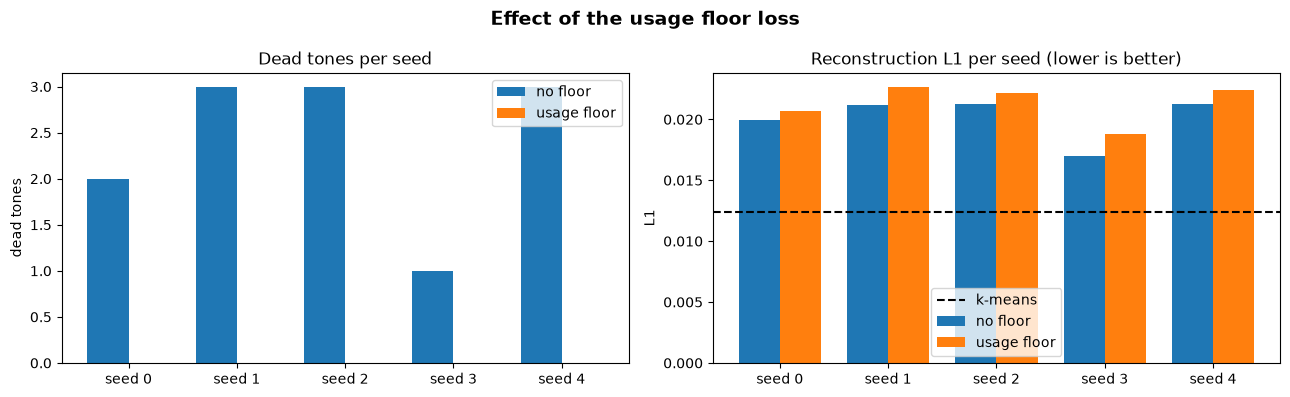

In [21]:
x = np.arange(len(SEEDS))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (config, group) in enumerate(runs.items()):
    offset = (i - 0.5) * width
    axes[0].bar(x + offset, [r["dead"] for r in group], width, label=config)
    axes[1].bar(x + offset, [r["recon_l1"] for r in group], width, label=config)

axes[1].axhline(kmeans_run["recon_l1"], color="black", linestyle="--", label="k-means")

axes[0].set_title("Dead tones per seed")
axes[0].set_ylabel("dead tones")
axes[1].set_title("Reconstruction L1 per seed (lower is better)")
axes[1].set_ylabel("L1")
for ax in axes:
    ax.set_xticks(x, [f"seed {s}" for s in SEEDS])
    ax.legend()

fig.suptitle("Effect of the usage floor loss", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/03_floor_effect.png", dpi=120, bbox_inches="tight")
plt.show()

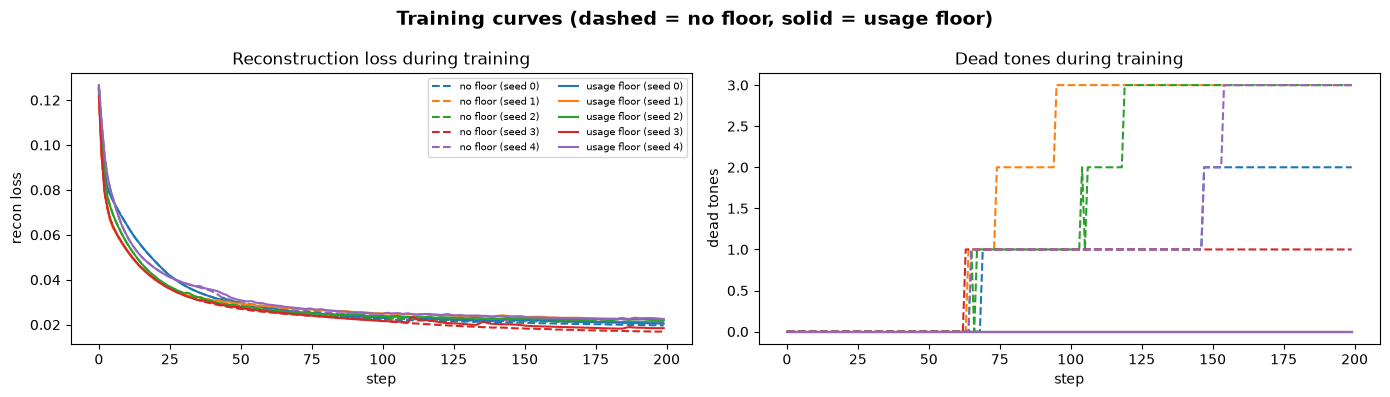

In [22]:
styles = {"no floor": "--", "usage floor": "-"}
colors = plt.cm.tab10.colors

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for config, group in runs.items():
    for run in group:
        color = colors[run["seed"] % len(colors)]
        axes[0].plot(run["recon_history"], styles[config], color=color, label=run["name"])
        axes[1].plot(run["dead_history"], styles[config], color=color)

axes[0].set_title("Reconstruction loss during training")
axes[0].set_xlabel("step")
axes[0].set_ylabel("recon loss")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_title("Dead tones during training")
axes[1].set_xlabel("step")
axes[1].set_ylabel("dead tones")

fig.suptitle("Training curves (dashed = no floor, solid = usage floor)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/03_loss.png", dpi=120, bbox_inches="tight")
plt.show()

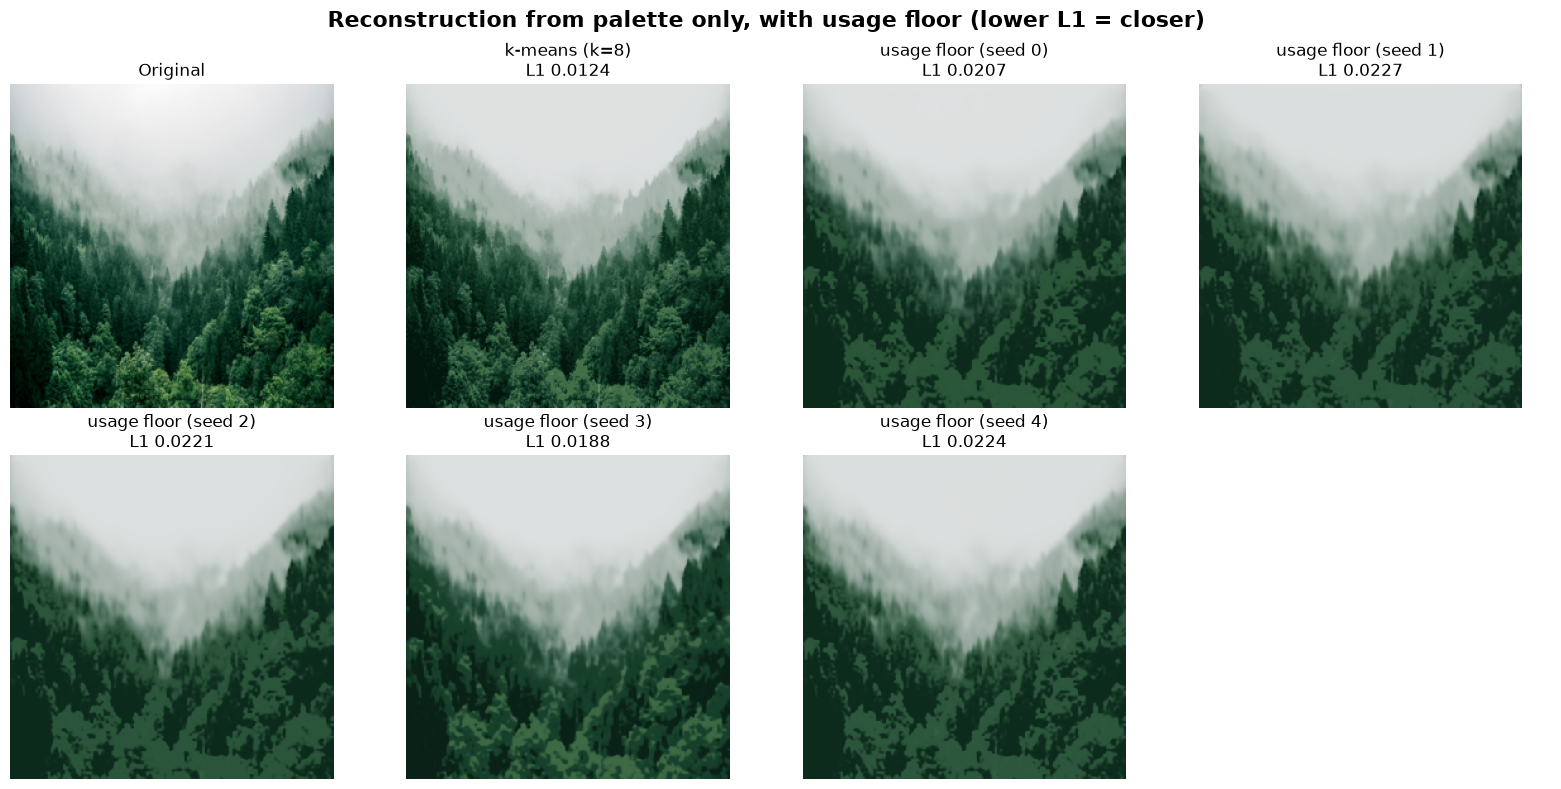

In [23]:
floor_runs = runs["usage floor"]

show_grid(
    [image_np, kmeans_run["recon_rgb"]] + [r["recon_rgb"] for r in floor_runs],
    ["Original", f"{kmeans_run['name']}\nL1 {kmeans_run['recon_l1']:.4f}"]
    + [f"{r['name']}\nL1 {r['recon_l1']:.4f}" for r in floor_runs],
    "figures/03_reconstruction.png",
    suptitle="Reconstruction from palette only, with usage floor (lower L1 = closer)",
)

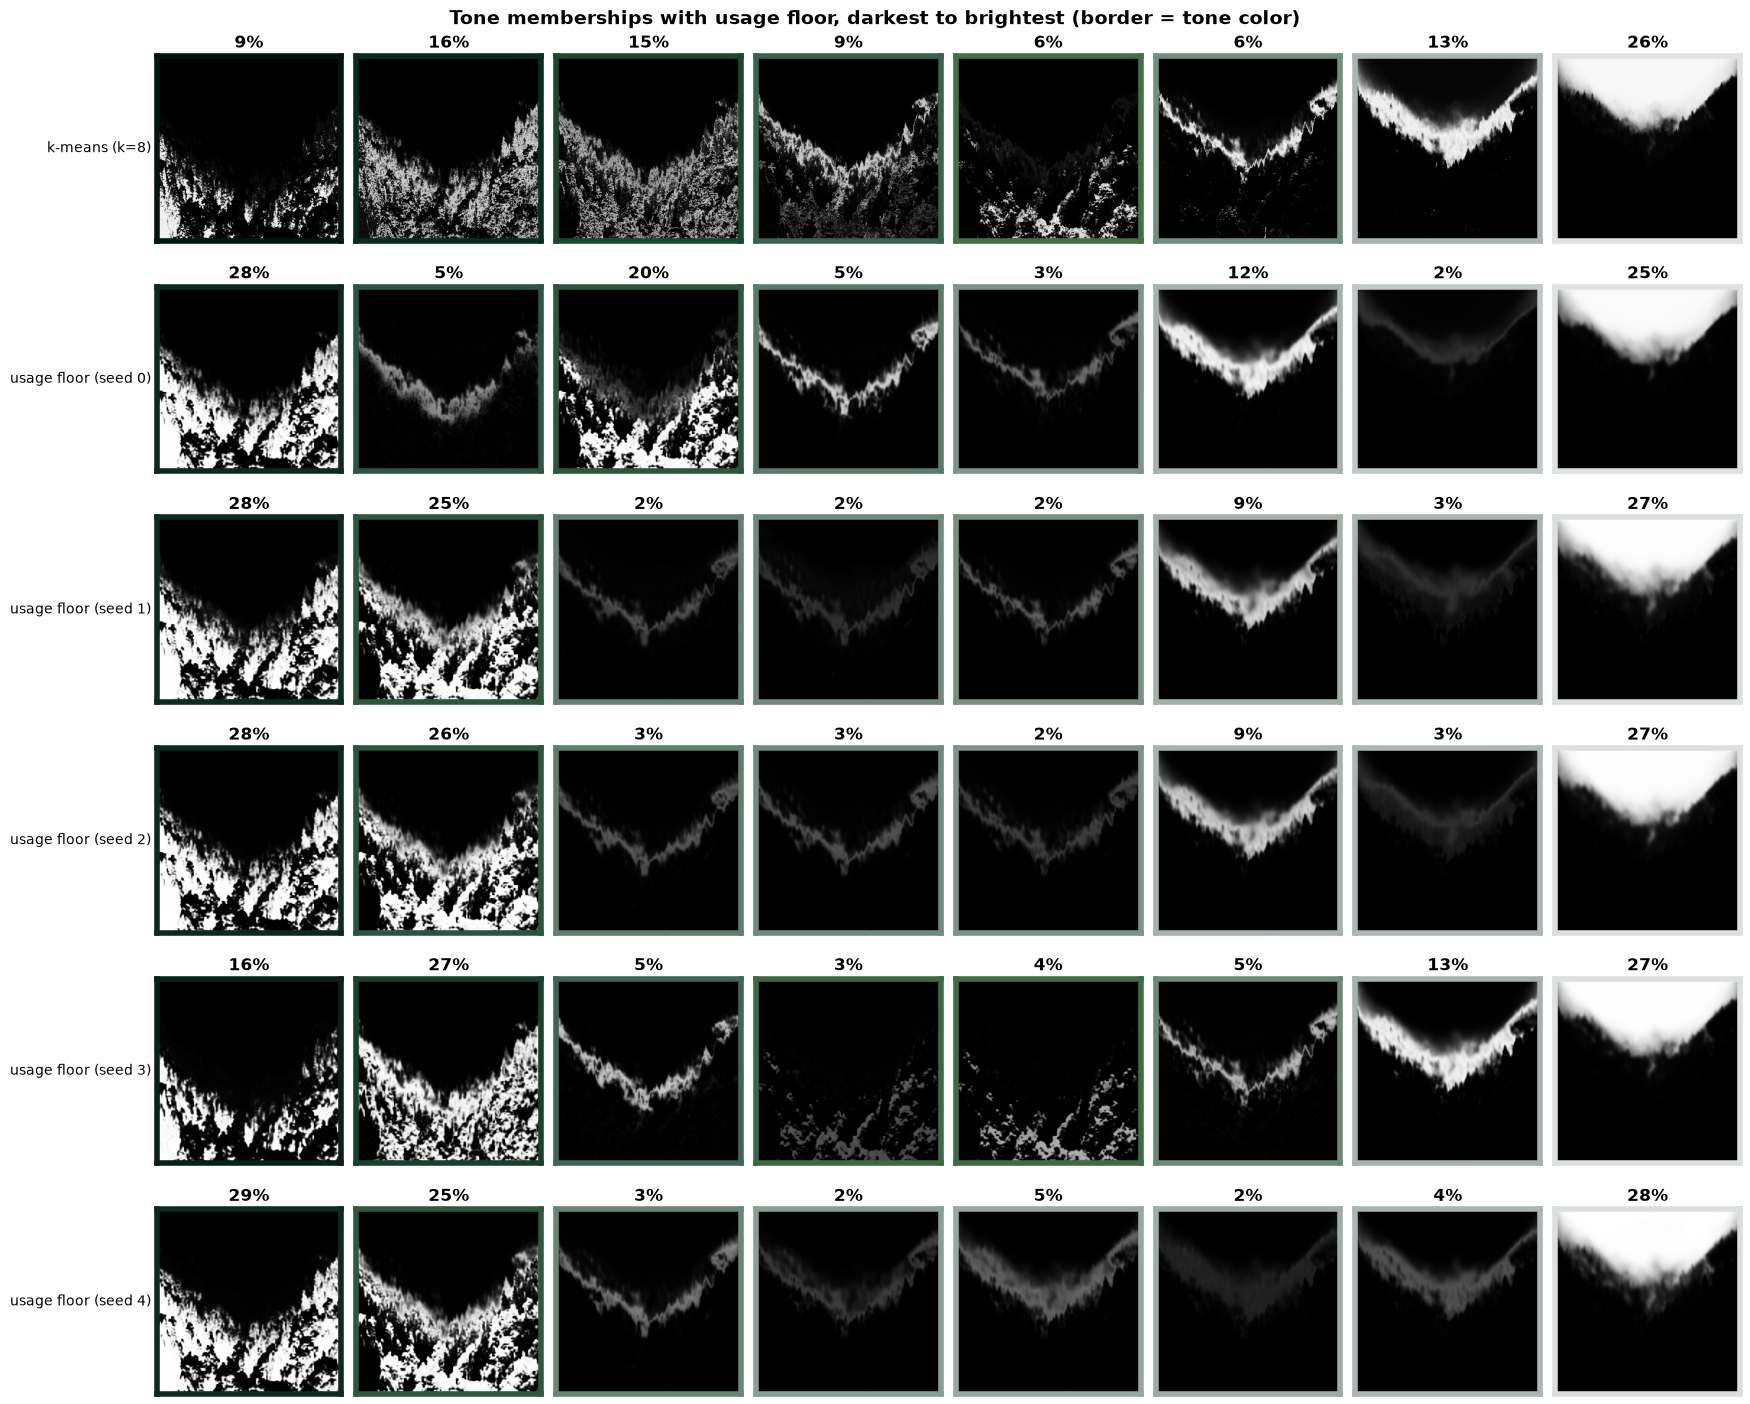

In [24]:
show_tone_maps(
    [kmeans_run] + floor_runs,
    "figures/03_tone_maps.png",
    "Tone memberships with usage floor, darkest to brightest (border = tone color)",
)

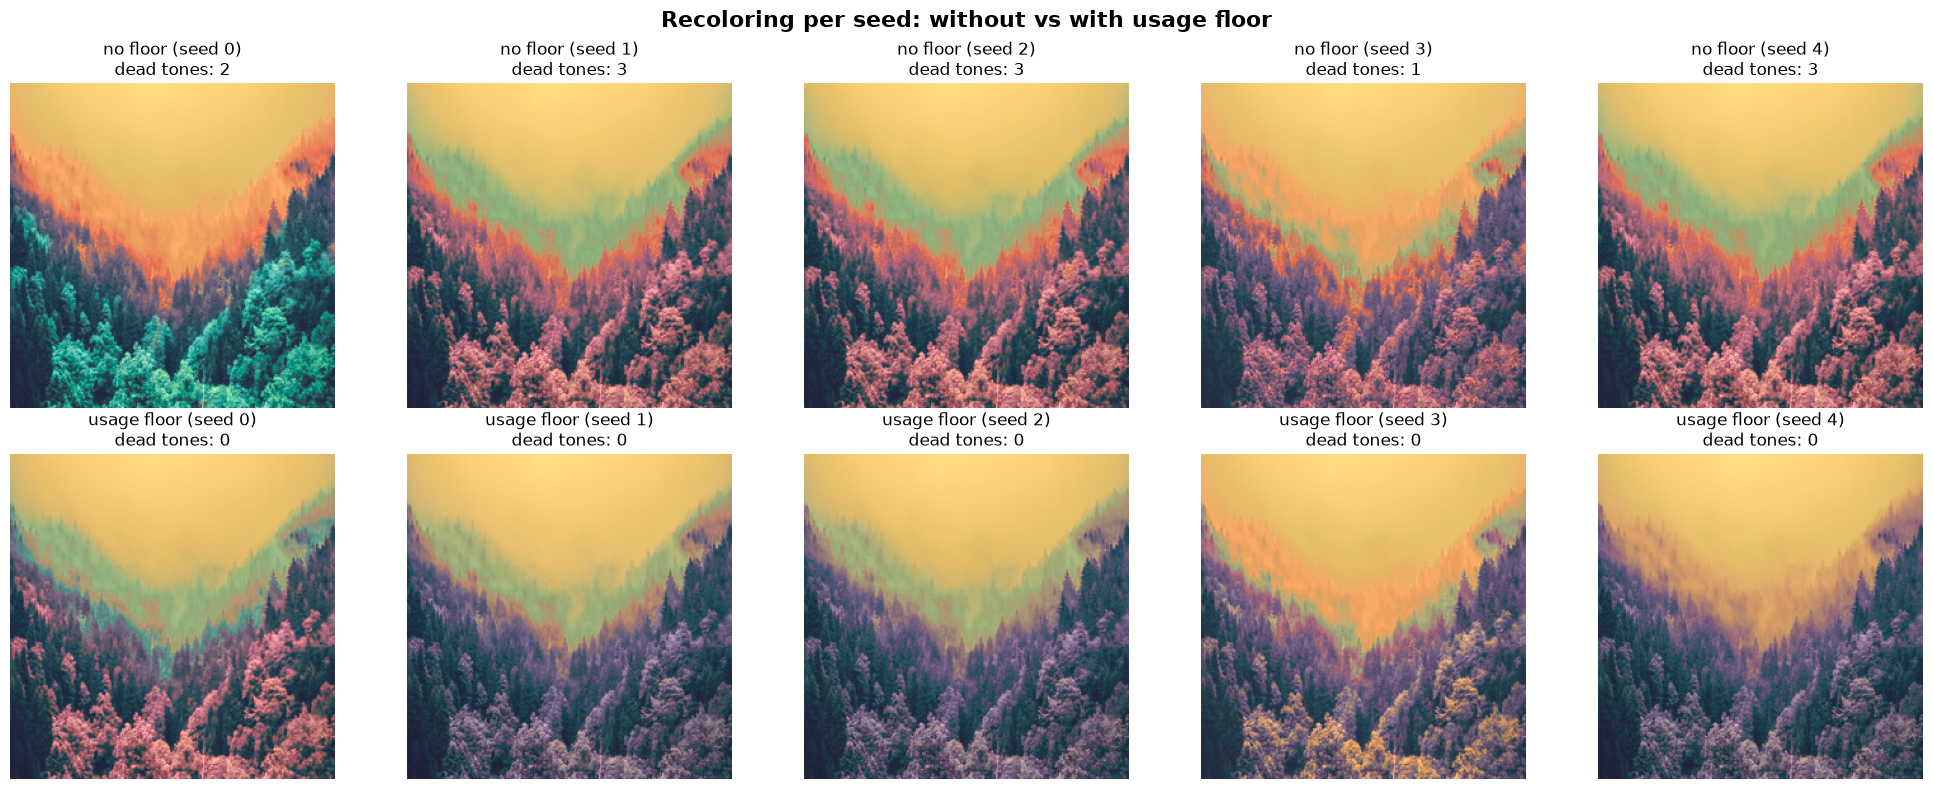

In [25]:
fig, axes = plt.subplots(len(CONFIGS), len(SEEDS), figsize=(4 * len(SEEDS), 4 * len(CONFIGS)))
for r, (config, group) in enumerate(runs.items()):
    for c, run in enumerate(group):
        ax = axes[r, c]
        ax.imshow(run["recolored"])
        ax.set_title(f"{run['name']}\ndead tones: {run['dead']}")
        ax.axis("off")

fig.suptitle("Recoloring per seed: without vs with usage floor", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/03_recolor_by_config.png", dpi=120, bbox_inches="tight")
plt.show()

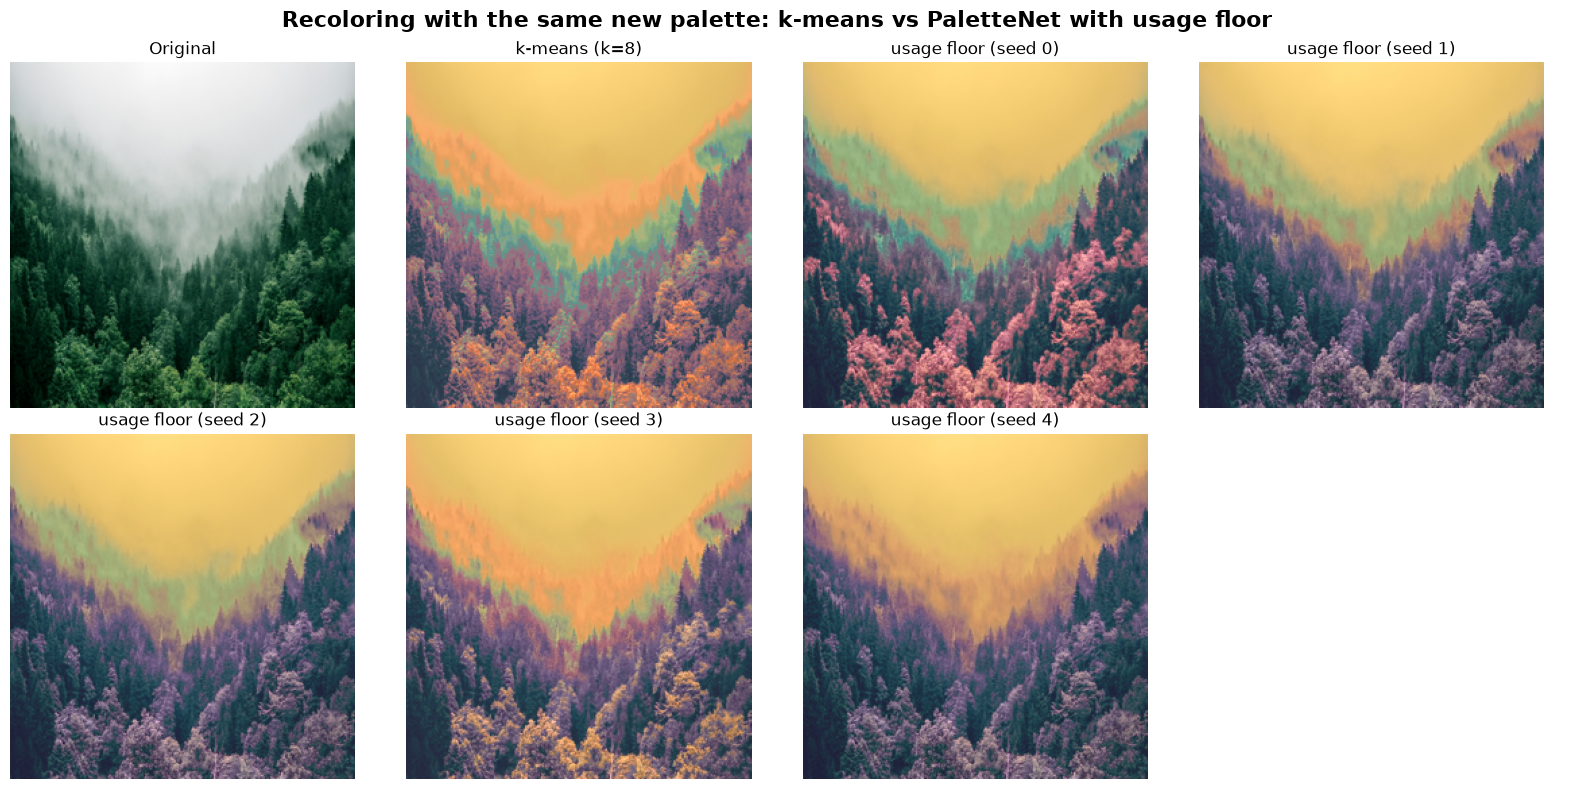

In [26]:
show_grid(
    [image_np, kmeans_run["recolored"]] + [r["recolored"] for r in floor_runs],
    ["Original", kmeans_run["name"]] + [r["name"] for r in floor_runs],
    "figures/03_recolor_comparison.png",
    suptitle="Recoloring with the same new palette: k-means vs PaletteNet with usage floor",
)

## Conclusions

**The floor removes dead tones, but only half of the problem.** Dead tones drop
from 2.4 to 0 per seed on average. Tones without a region, those that are never
the strongest tone in any pixel, only drop from 2.4 to 1.6. The network met the
floor by spreading a faint weight of the rescued tones along the fog border.
In the tone maps, seeds 1, 2 and 4 show several dim copies of the same band,
each sitting right at the 2-3% floor.

**Faint tones cost accuracy.** Reconstruction L1 gets worse in every seed,
from 0.0201 ± 0.0016 to 0.0213 ± 0.0014. Tones that own no region add color
mixing without describing anything new.

**When rescued tones find real regions, it works.** In seed 3, two rescued
tones moved into the forest and cover lit treetops (3% and 4%). They show up as
yellow highlights in the recolored image. This is the intended behavior, but it
happened in only one seed.

**Tones die mid-training, not at the start.** Without the floor, tones die
between steps 60 and 150, after the main structure is already formed. They are
absorbed gradually by neighboring tones.

**Recoloring is more consistent across seeds**, but part of the softer fog
transitions comes from faint tones blending colors, not from better regions.

**Design issue for the dataset step.** A per-image floor forces every image to
use all 8 tones, even simple images that need fewer. On a dataset this would
create faint tones everywhere. The floor should apply to usage averaged over a
batch: every tone must be useful somewhere, not in every image.